In [4]:
from IPython.display import display

In [5]:
import os, sys
sys.path.append(os.path.abspath(os.path.join("..")))

In [6]:
from src.data import load_csv
from src.models import MultipleLinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from src.metrics import *

In [7]:
df = load_csv("../data/hour.csv")

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[ns]
 1   season      17379 non-null  int64         
 2   yr          17379 non-null  int64         
 3   mnth        17379 non-null  int64         
 4   hr          17379 non-null  int64         
 5   holiday     17379 non-null  int64         
 6   weekday     17379 non-null  int64         
 7   workingday  17379 non-null  int64         
 8   weathersit  17379 non-null  int64         
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  cnt         17379 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(9)
memory usage: 1.9 MB


- instant: record index
	- dteday : date
	- season : season (1:springer, 2:summer, 3:fall, 4:winter)
	- yr : year (0: 2011, 1:2012)
	- mnth : month ( 1 to 12)
	- hr : hour (0 to 23)
	- holiday : weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)
	- weekday : day of the week
	- workingday : if day is neither weekend nor holiday is 1, otherwise is 0.
	+ weathersit : 
		- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
		- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
		- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
		- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
	- temp : Normalized temperature in Celsius. The values are divided to 41 (max)
	- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max)
	- hum: Normalized humidity. The values are divided to 100 (max)
	- windspeed: Normalized wind speed. The values are divided to 67 (max)
	- casual: count of casual users
	- registered: count of registered users
	- cnt: count of total rental bikes including both casual and registered

we have already neutralised `index`, `casual`, `registered` while loading the dataset, already transformed the `dteday` column from object to datetime. Now let us further transform our dataset after extracting what we need.

Yesterday, I log-transformed target column: `cnt` and after training our dataset only on `atemp, hum and windspeed` our test R2 score went up from 9.6 to 15.07,  RMSE dropped from 209 to 151. This is why data transformation is needed for our model to understand real hidden patterns.

### Phase 1: Building and Testing the Inference Engine: C1-C4

To build an inference function from scratch that mimics statsmodels, you need to assemble five core columns for every coefficient:
1. Coefficient ($\hat{\beta}$): The normal equation output $(X^T X)^{-1} X^T y$

2. Standard Error ($\text{SE}(\hat{\beta})$): Derived from the covariance matrix of the estimator: $\text{Cov}(\hat{\beta}) = \sigma^2 (X^T X)^{-1}$.The ingredient: Residual variance $\sigma^2 = \frac{\text{RSS}}{n - p - 1}$, where $n$ is rows and $p$ is features (minus the intercept).Take the square root of the diagonal elements of that covariance matrix.

3. t-statistic ($t$): $\hat{\beta} / \text{SE}(\hat{\beta})$ — how many standard errors the estimate is away from zero.

4. p-value ($p$): Calculated using the survival function (scipy.stats.t.sf) with degrees of freedom $n - p - 1$, assessing two-tailed probability.

5. 95% Confidence Interval: $\hat{\beta} \pm (t_{\text{crit}} \times \text{SE})$, where $t_{\text{crit}}$ comes from the t-distribution at $\alpha = 0.05$


1. What is Standard Error?

Imagine you collect a dataset of 1,000 bike rentals and fit a linear regression model. You get a slope coefficient $\hat{\beta}_{\text{temp}} = 45.2$ (each $1^\circ\text{C}$ increase in temperature adds ~45 rentals) [ISLP_website.pdf Sec 3.1.2].Now, imagine going back in time, collecting a different sample of 1,000 days, and fitting the model again. You might get $\hat{\beta}_{\text{temp}} = 43.8$. On a third sample, you might get $46.5$.The Standard Error ($\text{SE}(\hat{\beta}_j)$) measures the standard deviation of this sampling distribution—it quantifies how much your estimated coefficient "wobbles" across different random dataset draws from the same underlying population

In [9]:
## we are gonna use three functions for now, later we will use more:
feats = ['atemp', 'hum', 'windspeed']
X = df[feats]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)

 Training model to get beta_hat: our Coefficient ($\hat{\beta}$)

In [10]:
beta_hat = MultipleLinearRegression().fit(X_train, y_train).beta_hat

beta_hat


array([ 131.80296388,  391.12100534, -248.65229911,   55.55415169])

2. Standard error of coefficients: $$\operatorname{Var}(\hat{\boldsymbol{\beta}}) = \hat{\sigma}^2 (\mathbf{X}^T \mathbf{X})^{-1}$$

 $$\operatorname{SE}(\hat{\beta}_j) = \sqrt{\left[ \hat{\sigma}^2 (\mathbf{X}^T \mathbf{X})^{-1} \right]_{jj}} = \hat{\sigma} \cdot \sqrt{\left[ (\mathbf{X}^T \mathbf{X})^{-1} \right]_{jj}}$$

 here we have to first find: XTX_inv, then extract n, get p - 1, sse and then divide them and take root, we get rse, don't root it we get rse². 

use rse² and xtx_inv to get var(x) then compute sqrt of diagnoal element and you get your dear: Standard Error

Easier said that done, we don't know the complete thoery yet, but we are more focused on practical than theory !! 

In [11]:
## Add intercept: 
model = MultipleLinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_train)

X_train_design = model._add_intercept(X_train)
n = X_train_design.shape[0]
p = X_train_design.shape[1] - 1
beta_hat = model.beta_hat

## XTX for variance
XTX_inv = np.linalg.pinv(X_train_design.T @ X_train_design)

## SSE
sse = sum_of_squared_error(y_train, y_pred)
df = n - p - 1

sigma_hat_sq = sse / df

cov_beta = sigma_hat_sq * XTX_inv

# RSE
sigma_hat = np.sqrt(sigma_hat_sq)

## Standard Error
standard_error = np.sqrt(np.diag(cov_beta))
print("Standard Error:", standard_error)

t_stats =  beta_hat / standard_error
print(t_stats)

## p value
p_value = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=df))


## Confidence interval: 
t_crit = stats.t.ppf(0.975, df=df)
ci_lower = beta_hat - t_crit * standard_error
ci_upper = beta_hat + t_crit * standard_error



Standard Error: [ 6.27697919  6.84599379  6.36302234 10.25635763]
[ 20.9978335   57.13137019 -39.07770328   5.41655759]


In [12]:
def standard_error(X, y):
    n = len(y)
    X = np.column_stack([np.ones(n), X])
    p = X.shape[1] - 1

    XTX_inv = np.linalg.pinv(X.T @ X)
    beta_hat = XTX_inv @ X.T @ y

    residuals = y - (X @ beta_hat)
    SSE = np.sum(residuals**2)
    df = n - p - 1
    hat_sigma_sq = SSE / df

    cov_beta = hat_sigma_sq * XTX_inv
    SE = np.sqrt(np.diag(cov_beta))

    t_stats = beta_hat / SE

    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=df))

    t_crit = stats.t.ppf(0.975, df=df)
    ci_lower = beta_hat - t_crit * SE
    ci_upper = beta_hat + t_crit* SE

    return {"Beta Hat": beta_hat,
            "Standard Error":SE,
            "t_stats": t_stats,
            "CI lower": ci_lower,
            "CI upper": ci_upper}




In [13]:
pd.DataFrame(standard_error(X_train, y_train))

,Beta Hat,Standard Error,t_stats,CI lower,CI upper
0,131.802964,6.276979,20.997834,119.499239,144.106688
1,391.121005,6.845994,57.131370,377.701936,404.540075
2,-248.652299,6.363022,-39.077703,-261.124680,-236.179918
3,55.554152,10.256358,5.416558,35.450309,75.657994


==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        131.8030      6.277     20.998      0.000     119.499     144.107
atemp        391.1210      6.846     57.131      0.000     377.702     404.540
hum         -248.6523      6.363    -39.078      0.000    -261.125    -236.180
windspeed     55.5542     10.256      5.417      0.000      35.450      75.658
==============================================================================
Omnibus:                     2611.864   Durbin-Watson:                   0.430
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4985.594
Skew:                           1.157   Prob(JB):                         0.00
Kurtosis:                       4.804   Cond. No.                         12.4
==============================================================================

In [14]:
X_train.columns

Index(['atemp', 'hum', 'windspeed'], dtype='object')

In [15]:
pd.DataFrame(standard_error(X_train, y_train))


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
0,131.802964,6.276979,20.997834,119.499239,144.106688
1,391.121005,6.845994,57.131370,377.701936,404.540075
2,-248.652299,6.363022,-39.077703,-261.124680,-236.179918
3,55.554152,10.256358,5.416558,35.450309,75.657994


In [16]:
import statsmodels.api as sm

# 1. Add a constant column for the intercept
X_train_sm = sm.add_constant(X_train)

# 2. Initialize and fit the OLS model
# Note: statsmodels takes (endog, exog) -> y comes FIRST, then X
ols_model = sm.OLS(y_train, X_train_sm).fit()

# 3. View the full summary table
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.278
Model:                            OLS   Adj. R-squared:                  0.277
Method:                 Least Squares   F-statistic:                     1780.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:44:44   Log-Likelihood:                -88619.
No. Observations:               13903   AIC:                         1.772e+05
Df Residuals:                   13899   BIC:                         1.773e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        131.8030      6.277     20.998      0.0

YAYY! now that this is confirmed, let us interpret everything !! 

1. `hr` as normal
2. `hr` as cylical
3. `hr` as ome hot encoded values 

let us interpret it perfectly !! 

In [32]:
df = load_csv("../data/hour.csv")

In [33]:
X = df.iloc[:, :13]
y = df.iloc[:, -1]

In [34]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, shuffle=False, test_size=0.2
)

In [35]:
def split_sets_tr_val(X_train, y_train, feature_cols):

    split_idx = int(len(X_train) * 0.8)
    X_tr = X_train.iloc[:split_idx][feature_cols]
    y_tr = y_train.iloc[:split_idx]

    X_val = X_train.iloc[split_idx:][feature_cols]
    y_val = y_train.iloc[split_idx:]

    return X_tr, y_tr, X_val, y_val


## split, then take out features, apply the transformation, then get the summary 

get features from train split, transform the feature and then calculate the summary !! i dont need to over do this bye !! 

In [21]:
features = ['hr', 'atemp', 'hum', 'windspeed']
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)
print(X_tr.shape, y_tr.shape)
print(X_val.shape, y_val.shape)
# Save original hour column before transformation for plotting later
hr_val_original = X_val['hr'].copy()

def evaluate_variant(X_tr, y_tr, X_val, y_val):
        model = MultipleLinearRegression()
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        beta_hat = model.beta_hat

        mse_= mse(y_val, y_pred)
        mae= mean_absolute_error(y_val, y_pred)
        rmse= root_mse(y_val, y_pred)
        r2_score_= r2_score(y_val, y_pred)
        adj_r2 = adjusted_r2score(X_val, y_val, y_pred)
        sse= sum_of_squared_error(y_val, y_pred)
        sst= total_sum_of_squares(y_val)
        ssm = model_sum_of_squares(y_val, y_pred)
        metrics_dict ={
                "MSE": mse_,
                "MAE": mae,
                "RMSE": rmse,
                "R2": r2_score_,
                "Adjusted_R2": adj_r2,
                "SSE": sse,
                "SST": sst,
                "SSM": ssm,}

        metrics_df = pd.DataFrame(metrics_dict, index=[0])
        
        summary_stats = pd.DataFrame(standard_error(X_tr, y_tr))
        index = ['Intercept']
        index.extend(X_tr.columns)
        summary_stats.index = index
        return metrics_df, summary_stats, y_pred, y_val

(11122, 4) (11122,)
(2781, 4) (2781,)


In [22]:
metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
print(metrics)
print(summary)

            MSE         MAE  ...           SST           SSM
0  37281.847736  138.971641  ...  1.309673e+08  2.819459e+07

[1 rows x 8 columns]
             Beta Hat  Standard Error    t_stats    CI lower    CI upper
Intercept   42.163319        6.005370   7.020936   30.391727   53.934910
hr           6.148141        0.168630  36.459430    5.817597    6.478685
atemp      293.057657        6.514422  44.985980  280.288234  305.827080
hum       -151.914879        5.977449 -25.414668 -163.631739 -140.198019
windspeed   16.973215        9.313729   1.822387   -1.283346   35.229777


In [23]:
### for `hr` i am keeping X_tr, y_tr, x_val, y_val same !! 
# i will only transform the hr columb
features = ['hr', 'atemp', 'hum', 'windspeed']
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr['hr_sin'] = np.sin(2 * np.pi * X_tr['hr'] / 24.0)
X_tr['hr_cos'] = np.cos(2 * np.pi * X_tr['hr'] / 24.0)

X_val['hr_sin'] = np.sin(2 * np.pi * X_val['hr'] / 24.0)
X_val['hr_cos'] = np.cos(2 * np.pi * X_val['hr'] / 24.0)

X_tr = X_tr.drop(columns=['hr'])
X_val = X_val.drop(columns=['hr'])



metrics, summary , _, _= evaluate_variant(X_tr, y_tr, X_val, y_val)
print(metrics)
print(summary)

            MSE         MAE  ...           SST           SSM
0  33938.554991  127.364454  ...  1.309673e+08  3.918413e+07

[1 rows x 8 columns]
             Beta Hat  Standard Error    t_stats    CI lower    CI upper
Intercept   98.287131        5.120148  19.196151   88.250733  108.323529
atemp      238.266552        6.100567  39.056463  226.308359  250.224745
hum        -73.641273        5.761526 -12.781556  -84.934887  -62.347659
windspeed  -36.906315        8.614271  -4.284323  -53.791814  -20.020816
hr_sin     -68.430465        1.580387 -43.299813  -71.528304  -65.332626
hr_cos     -72.684458        1.520280 -47.809906  -75.664478  -69.704439


In [24]:
from sklearn.preprocessing import OneHotEncoder

In [25]:
def one_hot_encode(X_train, X_test, columns=[]):
    if not columns:
        raise ValueError("No column to OneHotEncode")

    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop='first')

    encoded_array = encoder.fit_transform(X_train[columns])
    encoded_df = pd.DataFrame(encoded_array, columns= encoder.get_feature_names_out(columns), index=X_train.index)

    X_train = X_train.drop(columns=columns).join(encoded_df)

    encoded_array = encoder.transform(X_test[columns])
    encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(columns), index=X_test.index)

    X_test = X_test.drop(columns=columns).join(encoded_df)

    X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

    return X_train, X_test

In [29]:
from sklearn.preprocessing import OneHotEncoder

features = ['hr', 'atemp', 'hum', 'windspeed']
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr'])
X_tr

,atemp,hum,windspeed,hr_1,hr_2,hr_3,hr_4,hr_5,hr_6,hr_7,hr_8,hr_9,hr_10,hr_11,hr_12,hr_13,hr_14,hr_15,hr_16,hr_17,hr_18,hr_19,hr_20,hr_21,hr_22,hr_23
0,0.2879,0.81,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.2727,0.80,0.0000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.2727,0.80,0.0000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.2879,0.75,0.0000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.2879,0.75,0.0000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11117,0.4394,0.38,0.1940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11118,0.4545,0.36,0.1343,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11119,0.4848,0.31,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11120,0.5000,0.27,0.2836,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
from sklearn.preprocessing import OneHotEncoder

features = ['hr', 'atemp', 'hum', 'windspeed']
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)


## dropping 1st column okay
encoder= OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')

encoded_array = encoder.fit_transform(X_tr[['hr']])
encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['hr']), index=X_tr.index,)
X_tr = X_tr.drop(columns=['hr']).join(encoded_df)


encoded_array = encoder.transform(X_val[['hr']])
encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['hr']), index=X_val.index,)
X_val = X_val.drop(columns=['hr']).join(encoded_df)
# Align columns so X_val has the exact same one-hot columns as X_tr
X_tr, X_val = X_tr.align(X_val, join="left", axis=1, fill_value=0)
X_tr


,atemp,hum,windspeed,hr_1,hr_2,hr_3,hr_4,hr_5,hr_6,hr_7,hr_8,hr_9,hr_10,hr_11,hr_12,hr_13,hr_14,hr_15,hr_16,hr_17,hr_18,hr_19,hr_20,hr_21,hr_22,hr_23
0,0.2879,0.81,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.2727,0.80,0.0000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.2727,0.80,0.0000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.2879,0.75,0.0000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.2879,0.75,0.0000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11117,0.4394,0.38,0.1940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11118,0.4545,0.36,0.1343,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11119,0.4848,0.31,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11120,0.5000,0.27,0.2836,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
metrics, summary , y_pred, y_val= evaluate_variant(X_tr, y_tr, X_val, y_val)

print(metrics)

print(summary)

            MSE         MAE        RMSE        R2  Adjusted_R2           SSE  \
0  24251.989624  110.033371  155.730503  0.485026     0.480164  6.744478e+07   

            SST           SSM  
0  1.309673e+08  4.896518e+07  
             Beta Hat  Standard Error    t_stats    CI lower    CI upper
Intercept    8.097039        5.856232   1.382636   -3.382217   19.576294
atemp      252.355171        5.018292  50.287066  242.518427  262.191915
hum        -93.209993        4.747333 -19.634181 -102.515609  -83.904376
windspeed  -43.176563        7.076329  -6.101548  -57.047427  -29.305700
hr_1       -13.442546        5.805250  -2.315584  -24.821869   -2.063223
hr_2       -19.577534        5.834914  -3.355240  -31.015003   -8.140066
hr_3       -27.250945        5.886653  -4.629277  -38.789832  -15.712059
hr_4       -29.151719        5.896231  -4.944128  -40.709379  -17.594058
hr_5       -16.328088        5.834277  -2.798648  -27.764309   -4.891867
hr_6        29.230424        5.809075   5.031

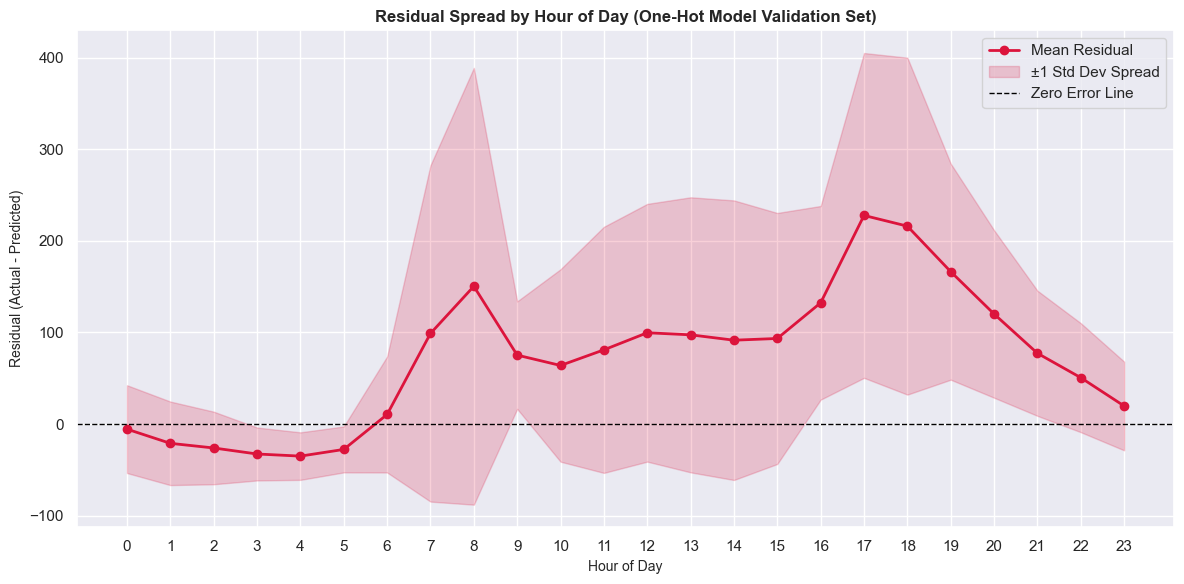

In [ ]:
residual = y_val - y_pred

# Build hourly summary DataFrame
hourly_summary = (
    pd.DataFrame({'hr': hr_val_original, 'residual': residual})
    .groupby('hr')
    .agg(mean_residual=('residual', 'mean'), std_residual=('residual', 'std'))
    .reset_index()
)

# Plotting with fill_between for standard deviation spread
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_summary['hr'],
    hourly_summary['mean_residual'],
    marker='o',
    color='crimson',
    linewidth=2,
    label='Mean Residual',
)

plt.fill_between(
    hourly_summary['hr'],
    hourly_summary['mean_residual'] - hourly_summary['std_residual'],
    hourly_summary['mean_residual'] + hourly_summary['std_residual'],
    color='crimson',
    alpha=0.2,
    label='±1 Std Dev Spread',
)

plt.axhline(
    0, color='black', linestyle='--', linewidth=1, label='Zero Error Line'
)

plt.title(
    'Residual Spread by Hour of Day (One-Hot Model Validation Set)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Hour of Day', fontsize=10)
plt.ylabel('Residual (Actual - Predicted)', fontsize=10)
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
model = MultipleLinearRegression()
model.fit(X_tr, y_tr)
residual = model.residual(X_tr, y_tr)


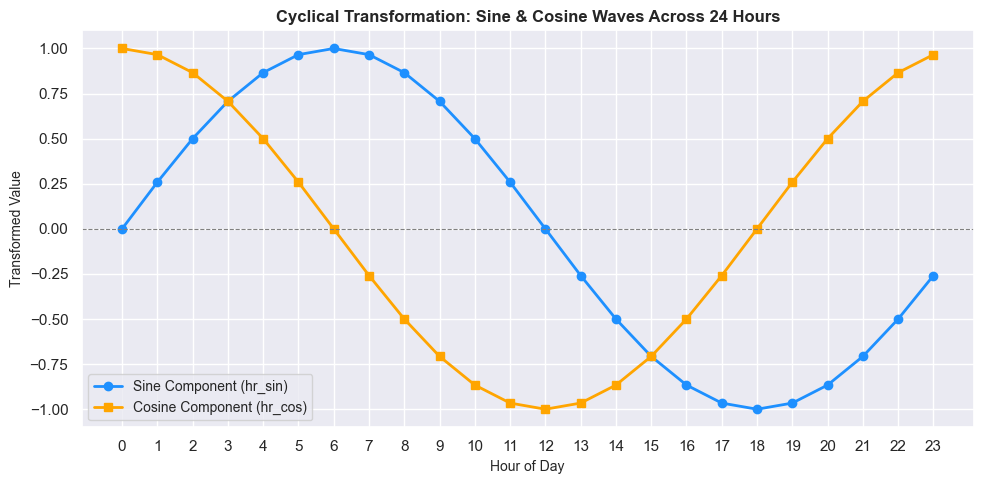

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="darkgrid")

hours = np.arange(24)
hr_sin = np.sin(2 * np.pi * hours / 24.0)
hr_cos = np.cos(2 * np.pi * hours / 24.0)

plt.figure(figsize=(10, 5))
plt.plot(
    hours,
    hr_sin,
    marker="o",
    linewidth=2,
    label="Sine Component (hr_sin)",
    color="dodgerblue",
)
plt.plot(
    hours,
    hr_cos,
    marker="s",
    linewidth=2,
    label="Cosine Component (hr_cos)",
    color="orange",
)

plt.title(
    "Cyclical Transformation: Sine & Cosine Waves Across 24 Hours",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Hour of Day", fontsize=10)
plt.ylabel("Transformed Value", fontsize=10)
plt.xticks(hours)
plt.axhline(0, color="grey", linewidth=0.8, linestyle="--")
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[ns]
 1   season      17379 non-null  int64         
 2   yr          17379 non-null  int64         
 3   mnth        17379 non-null  int64         
 4   hr          17379 non-null  int64         
 5   holiday     17379 non-null  int64         
 6   weekday     17379 non-null  int64         
 7   workingday  17379 non-null  int64         
 8   weathersit  17379 non-null  int64         
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  cnt         17379 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(9)
memory usage: 1.9 MB


15 and 200 when season included and hr not! 

In [45]:
## only season and other:
features = ["season", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['season'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,40015.203421,149.145228,200.038005,0.150305,0.148467,1.112823e+08,1.309673e+08,2.120536e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,97.584240,6.163049,15.833759,85.503570,109.664910
atemp,413.020317,10.295768,40.115541,392.838784,433.201850
hum,-202.488992,6.225384,-32.526346,-214.691850,-190.286135
windspeed,38.958521,9.757467,3.992688,19.832154,58.084888
season_2,-7.623823,3.680729,-2.071281,-14.838705,-0.408941
season_3,-56.859190,4.918903,-11.559324,-66.501112,-47.217268
season_4,16.558527,3.605359,4.592753,9.491383,23.625671


In [37]:
# Including Season Now:
features = ["season", "hr" , "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)


When trained on untransformed season and hr: the R2 was 0.20 and RMSE was 193

In [41]:
metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,37492.028148,139.149499,193.628583,0.203882,0.202448,1.042653e+08,1.309673e+08,2.886823e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,39.657661,6.028243,6.578643,27.841235,51.474086
season,4.869325,1.121516,4.341736,2.670955,7.067694
hr,6.155378,0.168503,36.529850,5.825083,6.485673
atemp,279.647770,7.204798,38.814103,265.525088,293.770452
hum,-156.775391,6.076666,-25.799576,-168.686734,-144.864049
windspeed,19.876810,9.330259,2.130360,1.587848,38.165773


0.48 and 156.41 is for transformed hr let us do it with not transformed hr and transformed season

In [42]:
features = ["season", "hr" , "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,24464.978925,110.461219,156.412848,0.480503,0.475408,6.803711e+07,1.309673e+08,4.964032e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,5.764343,5.862711,0.983221,-5.727613,17.256300
season,4.760224,0.843762,5.641667,3.106300,6.414147
atemp,239.208311,5.526648,43.282710,228.375098,250.041525
hum,-97.905129,4.813244,-20.340777,-107.339944,-88.470315
windspeed,-40.348777,7.084273,-5.695543,-54.235211,-26.462343
hr_1,-13.454063,5.797202,-2.320785,-24.817610,-2.090515
hr_2,-19.648861,5.826838,-3.372131,-31.070500,-8.227222
hr_3,-27.429329,5.878577,-4.665981,-38.952384,-15.906273
hr_4,-29.402410,5.888224,-4.993426,-40.944375,-17.860444
hr_5,-16.493760,5.826263,-2.830933,-27.914272,-5.073249


0.21 and 191.81 for transformed season !! let us not include hr and then try: 

In [43]:
features = ["season", "hr" , "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['season'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,36793.856993,137.369091,191.817249,0.218708,0.216735,1.023237e+08,1.309673e+08,2.842092e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,26.749168,6.184160,4.325432,14.627116,38.871220
hr,5.929707,0.168658,35.158134,5.599107,6.260307
atemp,347.864194,9.941645,34.990609,328.376806,367.351581
hum,-157.368110,6.043727,-26.038256,-169.214887,-145.521332
windspeed,16.800092,9.278142,1.810717,-1.386712,34.986896
season_2,3.611116,3.506424,1.029857,-3.262098,10.484330
season_3,-36.840039,4.701074,-7.836515,-46.054978,-27.625100
season_4,18.801575,3.420926,5.496048,12.095952,25.507197


0.496 and 153 high and low of the project ever !! when transformed both !

In [46]:
features = ["season", "hr" , "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr', 'season'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,23693.879725,108.57634,153.928164,0.496877,0.491573,6.589268e+07,1.309673e+08,4.775442e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,1.486464,5.940761,0.250214,-10.158485,13.131412
atemp,270.404297,7.777649,34.766843,255.158722,285.649872
hum,-101.835700,4.782340,-21.294114,-111.209938,-92.461462
windspeed,-43.914585,7.049711,-6.229275,-57.733272,-30.095897
hr_1,-13.266479,5.749599,-2.307374,-24.536716,-1.996241
hr_2,-19.299918,5.779395,-3.339436,-30.628560,-7.971276
hr_3,-26.956431,5.831277,-4.622732,-38.386771,-15.526090
hr_4,-28.587245,5.841550,-4.893778,-40.037722,-17.136769
hr_5,-15.460730,5.780930,-2.674436,-26.792382,-4.129079
hr_6,30.200373,5.755883,5.246871,18.917819,41.482927


not encoded: weather sit alone, no hr and season: score:0.13 rmse: 201.69

In [48]:
features = ["weathersit", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

# X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,40682.207641,151.517755,201.698308,0.136141,0.134896,1.131372e+08,1.309673e+08,1.976071e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,124.076787,5.955437,20.834203,112.403074,135.750501
weathersit,1.932714,2.048630,0.943418,-2.082963,5.948391
atemp,326.998415,6.849798,47.738406,313.571596,340.425233
hum,-204.228520,6.915875,-29.530394,-217.784862,-190.672178
windspeed,37.998305,9.942938,3.821638,18.508383,57.488226


untransformed season hr and weathersit: 0.20 and 193.65

In [49]:
features = ["season", "hr" ,"weathersit", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

# X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr'])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,37504.089322,139.179687,193.659726,0.203626,0.201904,1.042989e+08,1.309673e+08,2.892514e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,41.354998,6.066247,6.817229,29.464077,53.245919
season,4.687738,1.123689,4.171741,2.485109,6.890367
hr,6.197710,0.169341,36.598955,5.865771,6.529649
weathersit,-4.793126,1.948589,-2.459793,-8.612707,-0.973545
atemp,278.532449,7.217419,38.591700,264.385028,292.679870
hum,-148.897571,6.867748,-21.680697,-162.359577,-135.435566
windspeed,23.063737,9.417685,2.448982,4.603403,41.524072


transforming: hr, season and weathersit now: 0.49 and 153.5

In [50]:
features = ["season", "hr" , "weathersit" , "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr', "season", "weathersit"])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,23587.103237,108.058359,153.580934,0.499144,0.493312,6.559573e+07,1.309673e+08,4.889830e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,-17.811501,5.989637,-2.973720,-29.552255,-6.070747
atemp,259.268356,7.716657,33.598533,244.142335,274.394377
hum,-61.684976,5.463262,-11.290869,-72.393941,-50.976011
windspeed,-28.674599,7.027384,-4.080409,-42.449522,-14.899675
hr_1,-13.014728,5.682288,-2.290403,-24.153022,-1.876433
hr_2,-18.805783,5.711175,-3.292805,-30.000703,-7.610864
hr_3,-26.904415,5.762293,-4.669047,-38.199534,-15.609296
hr_4,-29.411742,5.773419,-5.094337,-40.728671,-18.094812
hr_5,-16.652111,5.712687,-2.914935,-27.849994,-5.454228
hr_6,29.147219,5.687842,5.124477,17.998035,40.296402


Now including all the needed features except temp: 0.286

In [52]:
features = ["holiday", "yr", "workingday", "season", "weathersit", "hr", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

# X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr'])

metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,33577.973429,146.77986,183.242936,0.286995,0.284679,9.338034e+07,1.309673e+08,1.802910e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,-18.500359,6.483689,-2.853369,-31.209540,-5.791179
holiday,-21.992435,6.789143,-3.239354,-35.300360,-8.684510
yr,78.671996,2.966734,26.518044,72.856669,84.487322
workingday,0.384056,2.408611,0.159451,-4.337249,5.105361
season,16.955226,1.182342,14.340370,14.637625,19.272826
weathersit,-4.575935,1.891048,-2.419788,-8.282725,-0.869145
hr,6.252483,0.164170,38.085480,5.930681,6.574285
atemp,295.080062,7.054932,41.826071,281.251145,308.908980
hum,-138.309556,6.675619,-20.718611,-151.394955,-125.224158
windspeed,25.296207,9.129359,2.770863,7.401043,43.191371


training on transformed hr, season and weathersit: 0.6002, 136.33: highest highest of them all !! 

In [53]:
features = ["holiday", "yr", "workingday", "season", "weathersit", "hr", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr', "season", "weathersit"])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,18588.114506,107.847092,136.338236,0.605294,0.600261,5.169355e+07,1.309673e+08,3.472438e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,-61.136524,5.850989,-10.448922,-72.605504,-49.667545
holiday,-18.815635,4.858049,-3.873085,-28.338275,-9.292995
yr,81.667902,2.152912,37.933694,77.447812,85.887993
workingday,1.808979,1.723440,1.049633,-1.569270,5.187228
atemp,242.529071,7.286148,33.286323,228.246924,256.811217
hum,-49.088757,5.151037,-9.529878,-59.185707,-38.991806
windspeed,-28.769933,6.605765,-4.355276,-41.718408,-15.821457
hr_1,-13.192974,5.341259,-2.470012,-23.662793,-2.723156
hr_2,-19.740899,5.368475,-3.677189,-30.264065,-9.217732
hr_3,-28.441755,5.416650,-5.250801,-39.059353,-17.824156


In [54]:
features = ["holiday", "yr", "season", "weathersit", "hr", "atemp", "hum", "windspeed"]
X_tr, y_tr, X_val, y_val = split_sets_tr_val(X_train_full, y_train_full, feature_cols=features)

X_tr, X_val = one_hot_encode(X_tr, X_val, columns=['hr', "season", "weathersit"])


metrics, summary, _, _ = evaluate_variant(X_tr, y_tr, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,R2,Adjusted_R2,SSE,SST,SSM
0,18589.346265,107.852492,136.342753,0.605268,0.600381,5.169697e+07,1.309673e+08,3.473052e+07


,Beta Hat,Standard Error,t_stats,CI lower,CI upper
Intercept,-60.031379,5.755502,-10.430260,-71.313187,-48.749571
holiday,-20.073341,4.707980,-4.263684,-29.301820,-10.844863
yr,81.705101,2.152630,37.955941,77.485563,85.924639
atemp,243.076539,7.267488,33.447118,228.830968,257.322110
hum,-49.172739,5.150440,-9.547289,-59.268517,-39.076960
windspeed,-28.761350,6.605790,-4.353960,-41.709875,-15.812825
hr_1,-13.190901,5.341283,-2.469613,-23.660767,-2.721035
hr_2,-19.739875,5.368499,-3.676982,-30.263089,-9.216661
hr_3,-28.462655,5.416638,-5.254671,-39.080230,-17.845079
hr_4,-32.012158,5.427386,-5.898264,-42.650800,-21.373515
